# imports

In [12]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [13]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [26]:
# specific
from typing import NamedTuple
from matplotlib import pyplot as plt

import jax
from jax import numpy as jnp
import optax

sys.path.append(os.path.join(os.getcwd(), '../src/'))
from utils_worm import read_utils

In [15]:
importlib.reload(read_utils)

<module 'utils_worm.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/../src/utils_worm/read_utils.py'>

# setup

In [16]:
dims = 2

save = False

In [17]:
organism = 'worm'

In [18]:
file_id = 19

In [19]:
max_noi = 20
neurons_of_interest = ['AVAR', 'AVAL',
					   'VB02', 'DB01', 'DD01'
					   ]
bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

In [20]:
state_key, state_label = analysis_utils.get_plot_class(organism)

filename, traces, behavior, classes, aux = analysis_utils.read_data(organism, file_id)

neuron_labels = []
for neuron in neurons_of_interest:
	if neuron not in neuron_labels and neuron in traces.columns:
		neuron_labels.insert(0, neuron)
neuron_labels = neuron_labels[:max_noi]

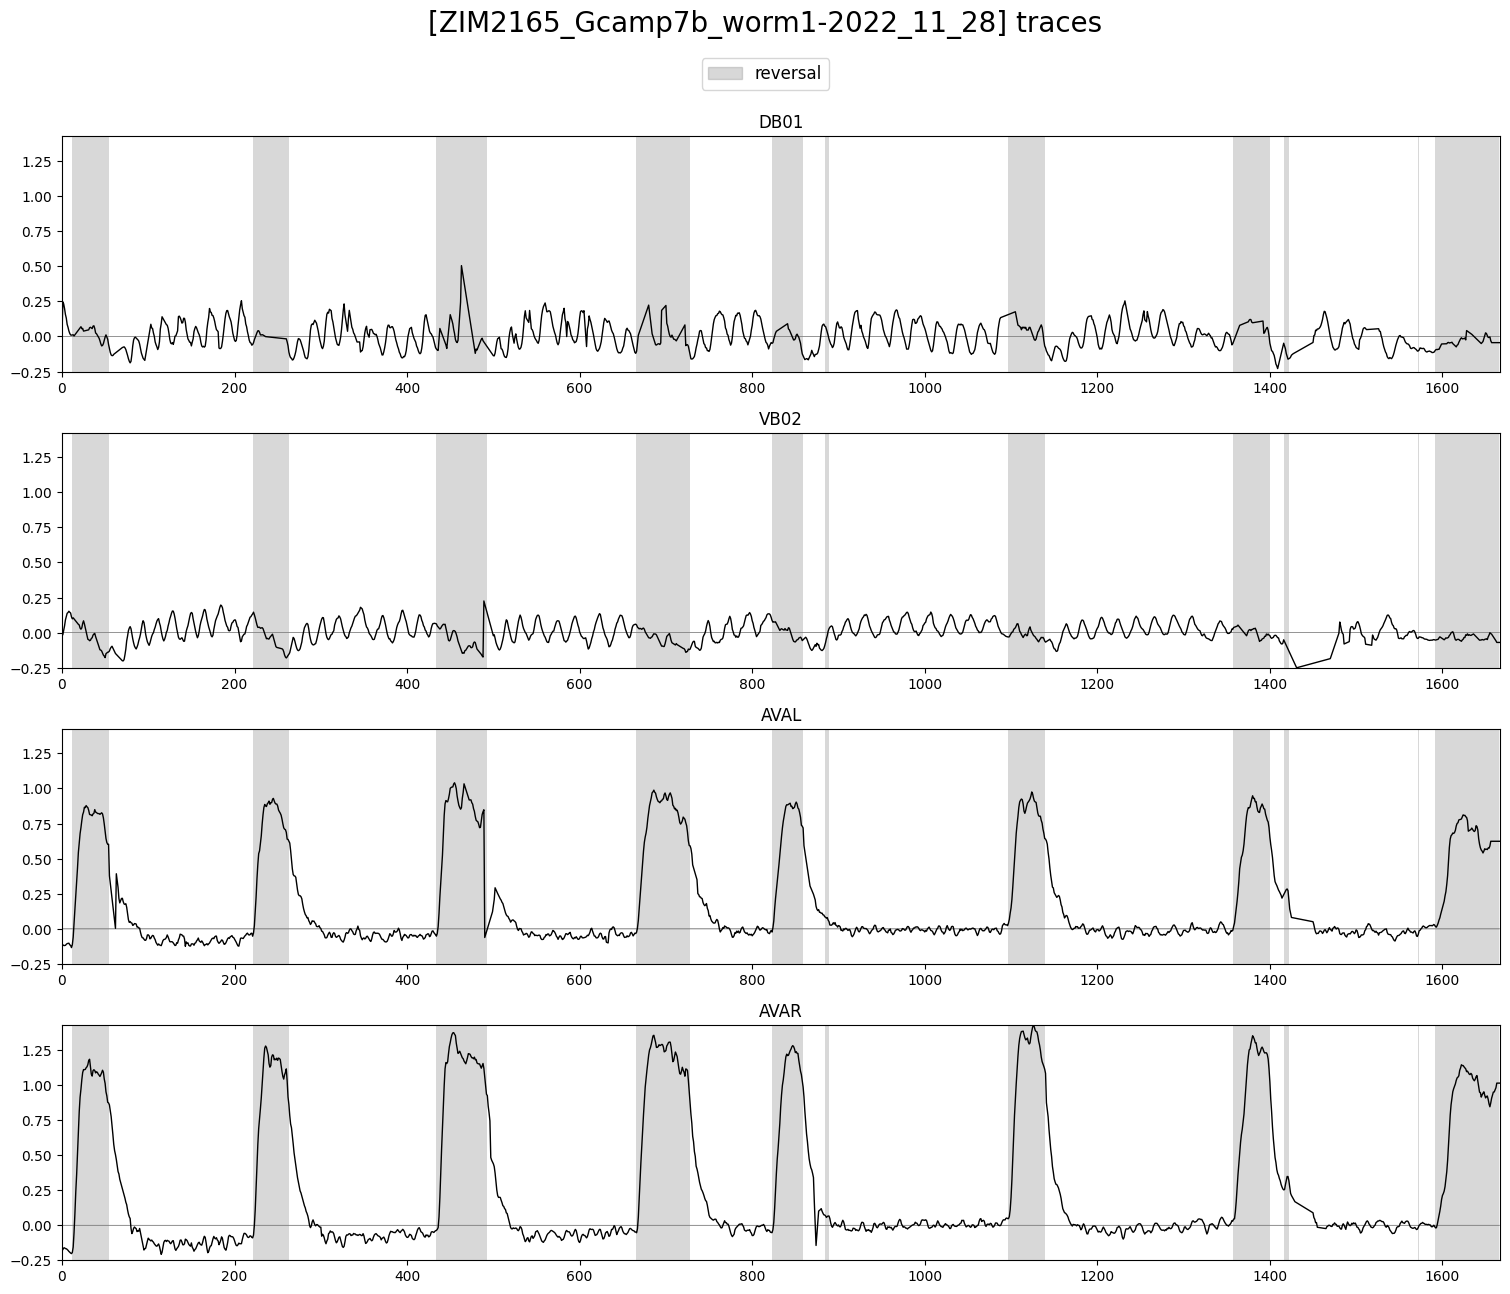

In [21]:
plot_utils.plot_traces(traces[neuron_labels],
					   classes[[state_key]],
					   label=state_label,
					   title=f'[{filename}] traces', ylimits=None)

# sklearn CCA

In [22]:
X = traces.values
Y = classes.values

In [24]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca([traces],
																	[classes[bhl_selection]],
																	scale=False,
																	n_cv=dims, n_pc=0)

X_l_h_df, Y_l_h_df = modes_manifold[0], modes_manifold_b[0]
X_l_h, Y_l_h = X_l_h_df.values, Y_l_h_df.values
X_rec_h_df, Y_rec_h_df = recos_manifold[0], recos_manifold_b[0]
X_rec_h, Y_rec_h = X_rec_h_df.values, Y_rec_h_df.values

# # def norm_temp(X_proj):
# # 	X_proj = X_proj - np.mean(X_proj, axis=0)
# # 	X_proj = X_proj / (np.linalg.norm(X_proj, axis=0) + 1e-6)
# # 	return X_proj
# # corr_a = np.array(norm_temp(X_l_h).T @ norm_temp(Y_l_h))

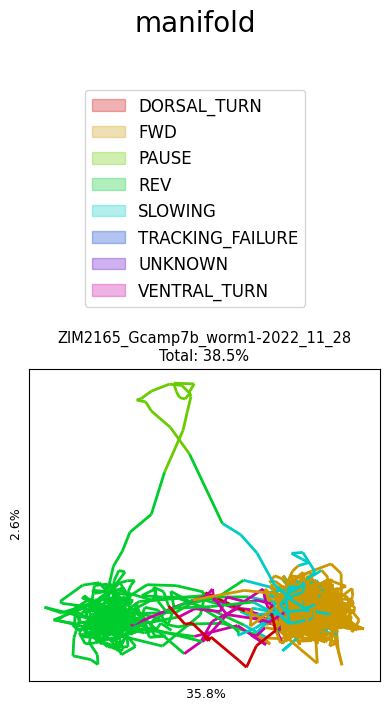

38.5%


In [25]:
# X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'CV{i}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_h_df],
							  [classes],
							  vars_expl_mans, None,
							  title='manifold', top_space=3.5,
							  save_path=None)

In [35]:
# plot_utils.plot_traces([X_l_h_df],
# 					   classes[[state_key]],
# 					   label=state_label,
# 					   title=f'[{filename}] cca neural modes', ylimits=None)

In [36]:
# Y_l_h_df = pd.DataFrame(data=Y_l_h, columns=[f'CV{i+1}' for i in range(dims)])
#
# plot_utils.plot_traces([Y_l_h_df],
# 					   classes[[state_key]],
# 					   label=state_label,
# 					   title=f'[{filename}] cca behavioral modes', ylimits=None)

In [37]:
# X_rec_h_df = pd.DataFrame(data=X_rec_h, columns=traces.columns)
#
# plot_utils.plot_traces([traces[neuron_labels], X_rec_h_df[neuron_labels]],
# 					   classes[[state_key]],
# 					   label=state_label,
# 					   title=f'[{filename}] cca neural reconstructions', ylimits=None)

In [38]:
# Y_rec_h_df = pd.DataFrame(data=Y_rec_h, columns=classes.columns)
#
# plot_utils.plot_traces([classes, Y_rec_h_df],
# 					   classes[[state_key]],
# 					   label=state_label,
# 					   title=f'[{filename}] cca behavioral reconstructions', ylimits=None)

# soft CCA

In [27]:
class Lambdas(NamedTuple):
	cca_lambdas: tuple[float, float]


@jax.jit
def orthonormalize_qr(A):
	Q, R = jnp.linalg.qr(A, mode='reduced')
	signs = jnp.sign(jnp.diag(R))  # fix sign ambiguity for a deterministic mapping
	return Q * jnp.where(signs == 0, 1.0, signs)


#@jax.jit
def norm(X_proj):
	X_proj = X_proj - jnp.mean(X_proj, axis=0)
	X_proj = X_proj / (jnp.linalg.norm(X_proj, axis=0) + 1e-6)
	return X_proj


@jax.jit
def get_reconstruction_matrix(X, Y):
	# return U.T
	# reconstruct Y (target) using X (predictor)
	return jnp.linalg.lstsq(X, Y)[0]


@jax.jit
def predict(params, N, S):
	prep_n = jax.lax.stop_gradient(params['prep']['N'])
	prep_s = jax.lax.stop_gradient(params['prep']['S'])

	N_mean, N_std = prep_n['mean'], prep_n['std']
	S_mean, S_std = prep_s['mean'], prep_s['std']

	U = params['model']['U']
	V = params['model']['V']

	U_orth = U
	# U_orth = orthonormalize_qr(U)
	V_orth = V
	# V_orth = orthonormalize_qr(V)

	N_zs = (N - N_mean) / N_std
	S_zs = (S - S_mean) / S_std

	N_man = N_zs @ U_orth
	S_man = S_zs @ V_orth

	# N_zs_rec = N_man @ U_orth.T
	N_zs_rec = N_man @ get_reconstruction_matrix(N_man, N_zs)
	N_rec = N_zs_rec * N_std + N_mean

	# S_zs_rec = N_man @ V_orth.T
	S_zs_rec = N_man @ get_reconstruction_matrix(S_man, S_zs)
	S_rec = S_zs_rec * S_std + S_mean

	return N_man, N_rec, S_man, S_rec


@jax.jit
def cca_loss(X_proj, Y_proj, ccadiag_lambda, ccaunit_lambda):
	corr = norm(X_proj).T @ norm(Y_proj)

	corr_diag = jnp.diag(jnp.diag(corr))
	corr_nondiag = corr - corr_diag

	return (ccadiag_lambda * jnp.mean(jnp.abs(corr_nondiag))
			+ ccaunit_lambda * jnp.mean(jnp.abs(corr_diag - jnp.eye(*corr_diag.shape))))


def loss_fn(params, N, S, lambdas):
	ccadiag_lambda, ccaunit_lambda = lambdas.cca_lambdas

	N_man, N_rec, S_man, S_rec = predict(params, N, S)

	man_loss = cca_loss(N_man, S_man, ccadiag_lambda, ccaunit_lambda)

	return man_loss

loss_and_grads = jax.jit(jax.value_and_grad(loss_fn, has_aux=False), static_argnums=(3,))


def update(opt_update, opt_state, params, N, S, lambdas):
	loss, grads = loss_and_grads(params, N, S, lambdas)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return opt_state, params_new, loss

update = jax.jit(update, static_argnums=(0, 5))

In [28]:
def init_params(N, S, n_dimensions, seeds, scale=False):
	return {
		'prep': {
			'N': {
				'mean': N.mean(axis=0),
				'std': jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std) if scale else jnp.ones((N.shape[1],)),
			},
			'S': {
				'mean': S.mean(axis=0),
				'std': jnp.where((S_std := jnp.std(S, axis=0)) == 0.0, 1.0, S_std),
			},
		},
		'model': {
			'U': 1E-3 * jax.random.normal(seeds[0], (N.shape[1], n_dimensions)),
			'V': 1E-3 * jax.random.normal(seeds[1], (S.shape[1], n_dimensions))
		}
	}


def train(N, S, hyperparams, scale=False):
	lambdas = Lambdas(cca_lambdas=(hyperparams['ccadiag_lambda'], hyperparams['ccaunit_lambda']))

	max_epochs = hyperparams['max_epochs']
	n_dimensions = hyperparams['dimensions']
	learning_rate = hyperparams['learning_rate']

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)
	params = init_params(N, S, n_dimensions, seeds, scale)
	# optimizer = optax.adam(learning_rate)
	optimizer = optax.adam(
		learning_rate=optax.cosine_decay_schedule(
			init_value=learning_rate,
			decay_steps=max_epochs,
			alpha=1E-4
		)
	)
	optimizer = optax.masked(optimizer, {'prep': False, 'model': True})
	opt_state = optimizer.init(params)

	losses_train = []
	for epoch in range(max_epochs):
		opt_state, params, loss_train = update(optimizer.update, opt_state, params, N, S, lambdas)
		losses_train.append(loss_train)

	return params, losses_train

In [29]:
hyperparameters = {
	'max_epochs': 10000,
	'learning_rate': 1E-0,
	'ccadiag_lambda': 0.6,
	'ccaunit_lambda': 1.0 - 0.6,
	'dimensions': dims
}

# splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces.shape[0]),
# 															   classes[[state_key]].values))
#
# results = list()
# for i in range(len(splits)):

params, losses_train = train(X, Y, hyperparameters, scale=False)
X_l_s, X_rec_s, Y_l_s, Y_rec_s = predict(params, X, Y)

# corr_n = np.array(norming(X_l_s).T @ norming(Y_l_s) / norming(X_l_s).shape[0])

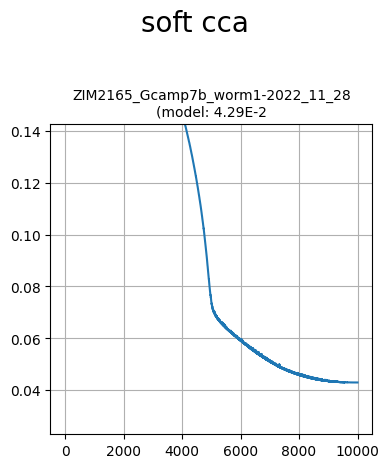

In [30]:
losses = np.array(losses_train)

plot_utils.plot_loss(filename,
					 losses,
					 title='soft cca', ylimits=0.2, plots_per_row=1)

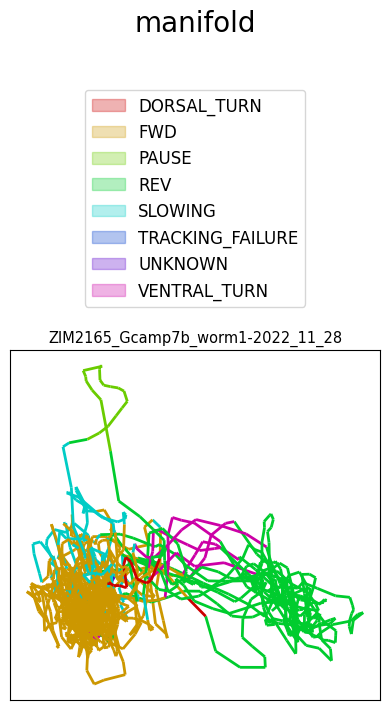

In [34]:
# X_l_s_pp, vars_expl = train_utils.postprocess_manifold(X_l_s, X, lambda X: X @ get_reconstruction_matrix(X_l_s, X), scale=False, align=True)

X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'CV{i+1}' for i in range(dims)])
# X_l_s_pp_df = pd.DataFrame(data=X_l_s_pp, columns=[f'PC{i+1}' for i in range(dims)])

if dims > 1:
	plot_utils.plot_manifolds([filename],
							  [X_l_s_df],
							  [classes],
							  None, None,
							  title='manifold', top_space=3.5,
							  save_path=None)

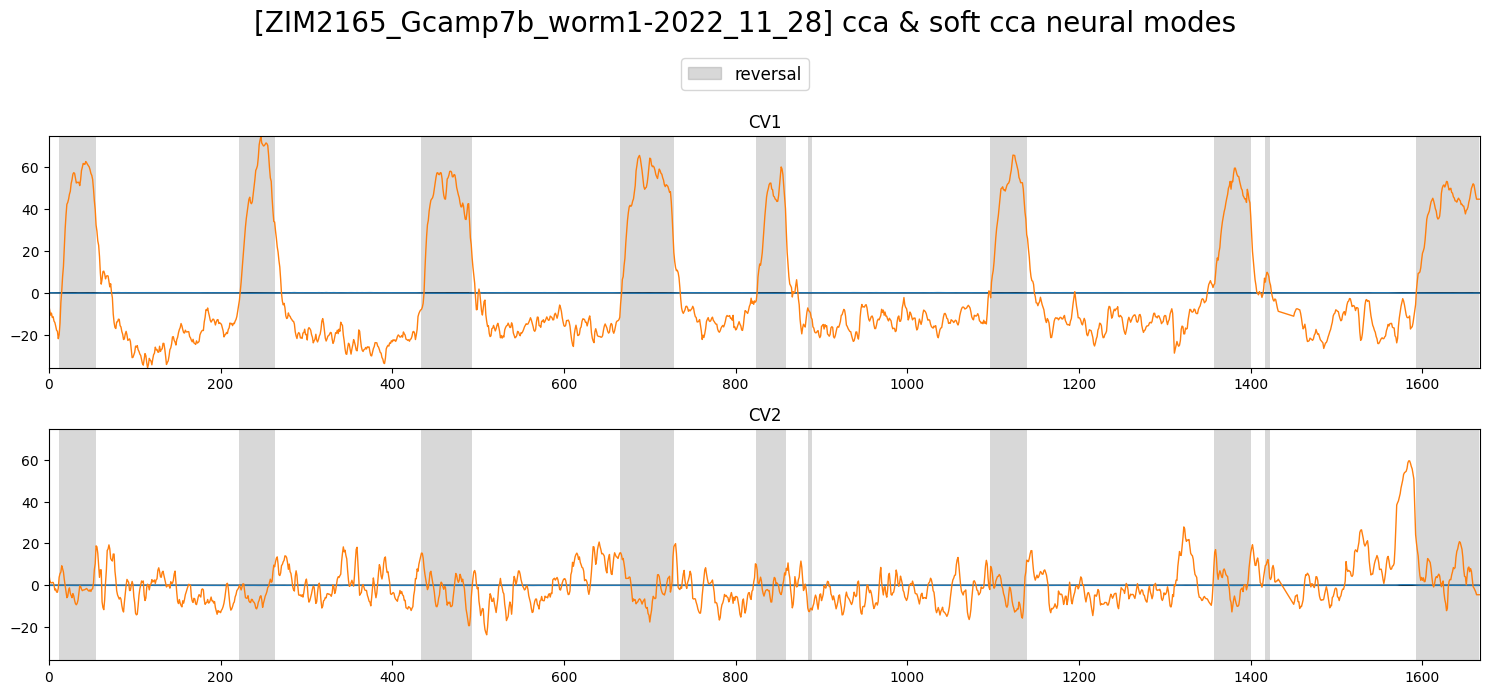

In [35]:
dummy = pd.DataFrame(np.zeros(X_l_h_df.shape), columns=X_l_h_df.columns)

plot_utils.plot_traces([dummy, X_l_h_df, X_l_s_df],
					   classes[[state_key]],
					   label=state_label,
					   title=f'[{filename}] cca & soft cca neural modes', ylimits=None)

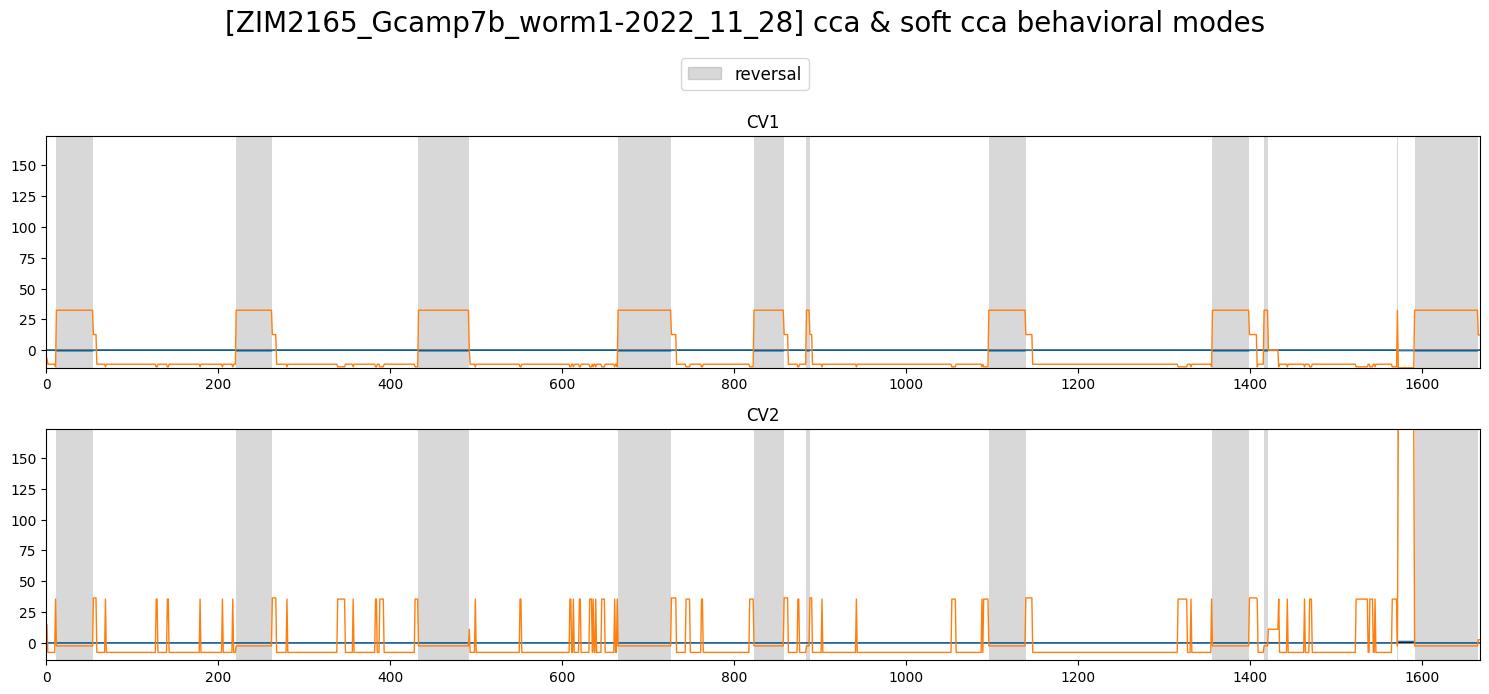

In [36]:
dummy = pd.DataFrame(np.zeros(Y_l_h_df.shape), columns=Y_l_h_df.columns)

Y_l_s_df = pd.DataFrame(data=Y_l_s, columns=[f'CV{i+1}' for i in range(dims)])

plot_utils.plot_traces([dummy, Y_l_h_df, Y_l_s_df],
					   classes[[state_key]],
					   label=state_label,
					   title=f'[{filename}] cca & soft cca behavioral modes', ylimits=None)

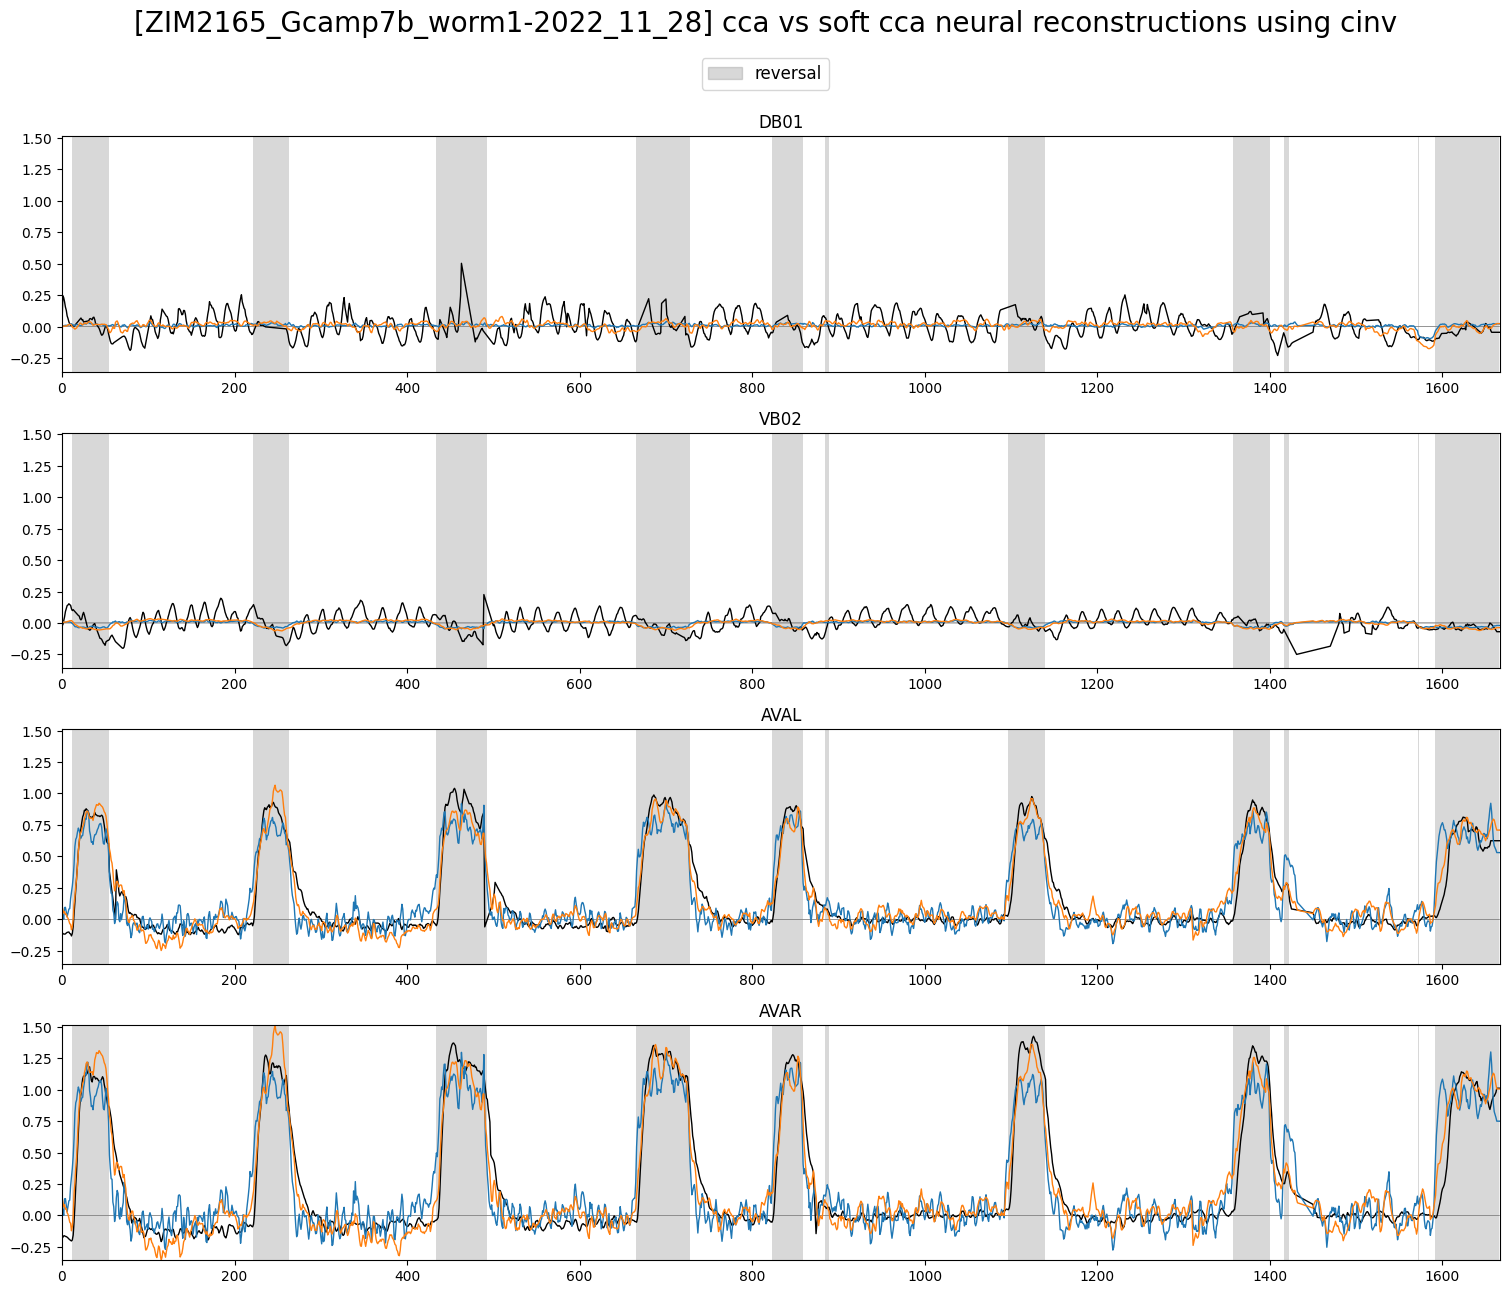

In [37]:
X_rec_s_df = pd.DataFrame(data=X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces[neuron_labels], X_rec_h_df[neuron_labels], X_rec_s_df[neuron_labels]],
					   classes[[state_key]],
					   label=state_label,
					   title=f'[{filename}] cca vs soft cca neural reconstructions using cinv', ylimits=None)

In [49]:
# Y_rec_s_cinv_df = pd.DataFrame(data=Y_rec_s, columns=classes.columns)
#
# plot_utils.plot_traces([classes, Y_rec_h_df, Y_rec_s_cinv_df],
# 					   classes[[state_key]],
# 					   label=state_label,
# 					   title=f'[{filename}] cca vs soft cca behavioral reconstructions using cinv', ylimits=None)

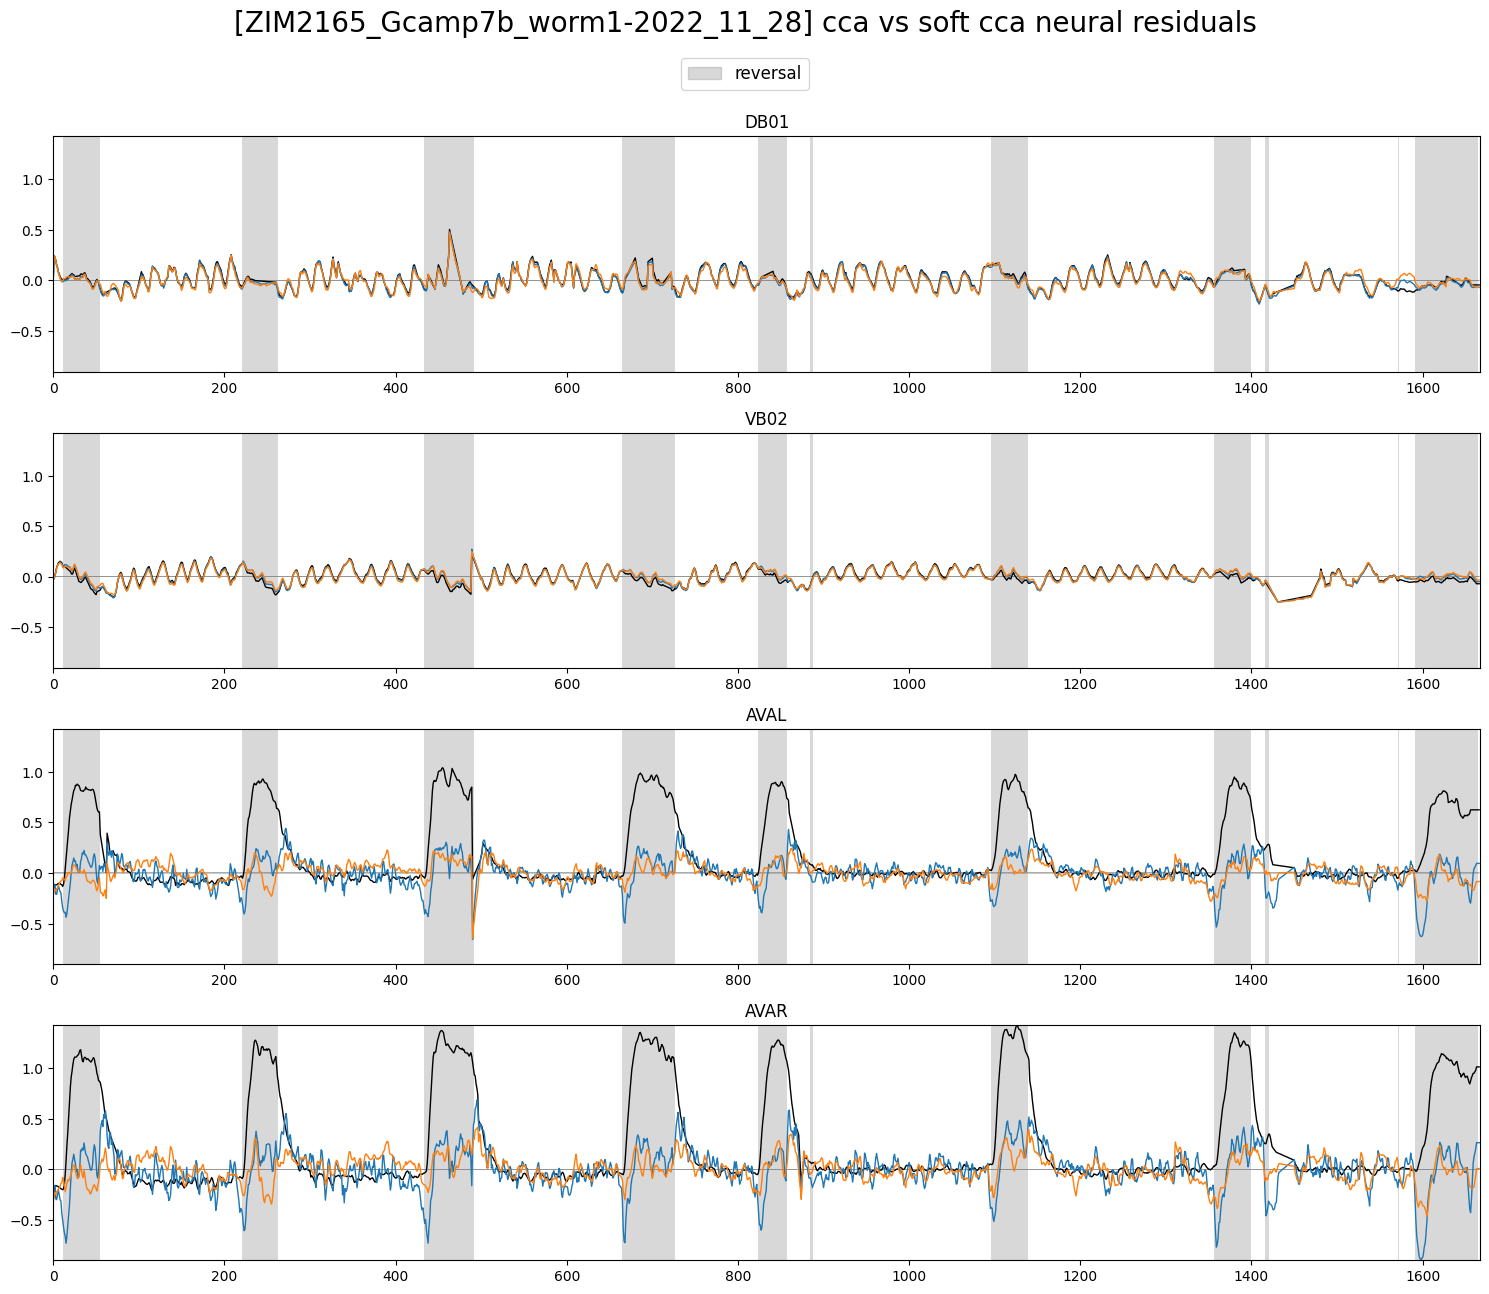

In [38]:
X_res_h_df = pd.DataFrame(data=X - X_rec_h, columns=traces.columns)
X_res_s_df = pd.DataFrame(data=X - X_rec_s, columns=traces.columns)

plot_utils.plot_traces([traces[neuron_labels], X_res_h_df[neuron_labels], X_res_s_df[neuron_labels]],
					   classes[[state_key]],
					   label=state_label,
					   title=f'[{filename}] cca vs soft cca neural residuals', ylimits=None)

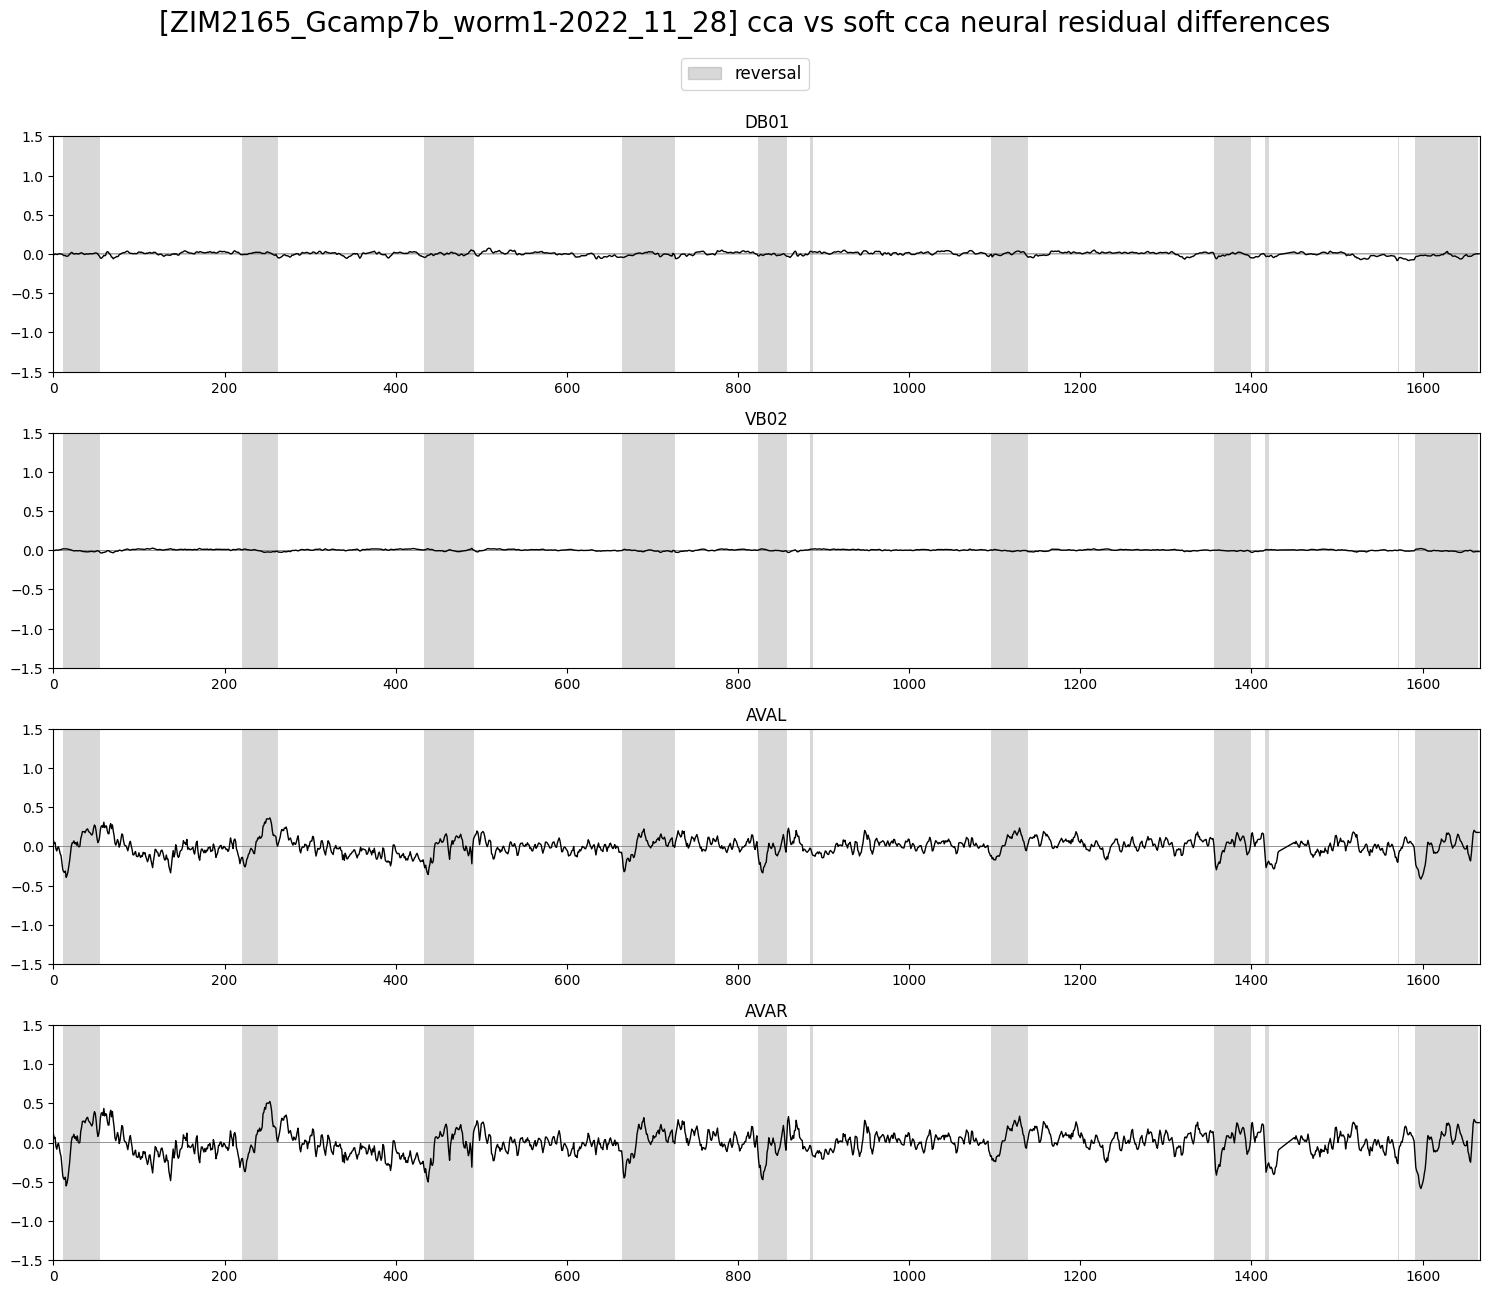

In [39]:
plot_utils.plot_traces([X_res_h_df[neuron_labels] - X_res_s_df[neuron_labels]],
					   classes[[state_key]],
					   label=state_label,
					   title=f'[{filename}] cca vs soft cca neural residual differences', ylimits=(-1.5, 1.5))